#Crude Oil Price Volatility & Procurement Risk

**Author:**  Oloruntoba Oluwatoyin Praise
**Tools:** Python (pandas), SQL (SQLite), matplotlib, Google Colab
**Data:** U.S. Energy Information Administration (EIA)  real, live government data, pulled directly from their API

---

## The problem

Oil prices go up and down all the time. If you run a company that buys fuel or crude oil regularly, that's a real risk, buy in the wrong week, and you overpay by a lot.

My manager asks: **"When should we be worried about oil prices, when is it safe to buy, and is this actually about supply running low, or is something else going on?"**

To answer that, I looked at two real oil prices the whole world watches:
- **WTI**: the main U.S. oil price
- **Brent**: the main global oil price

## What this notebook actually does, step by step

1. **Gets real weekly oil prices** straight from the U.S. government's own energy data system (no downloaded file, connected directly).
2. **Checks the data isn't broken**: no weird gaps, no duplicate entries.
3. **Measures how much prices actually swing** week to week: not just "oil costs $93," but "how wild are the ups and downs."
4. **Compares the U.S. price to the world price**: do they move together, or separately?
5. **Tries to check U.S. oil production too** (this part is a best guess at the right data address if it doesn't work, the rest of the notebook still runs fine without it).
6. **Draws charts** so the patterns are visible, not just numbers in a table.
7. **Writes out the findings in plain sentences**, automatically, using the real numbers once this runs.
8. **States honestly what this analysis can and can't tell us.**

## Step 1: Get real oil prices, straight from the source

Instead of downloading a file, this code asks the U.S. government's energy data system directly, over the internet, for real weekly oil prices going back years.

**Before running this, replace `PASTE_YOUR_EIA_API_KEY_HERE` below with your own key** (the one you got from eia.gov). Think of this key like a password that proves you're allowed to ask for the data keep it private, and I will not paste mine into a public github.

In [ ]:
import requests
import pandas as pd

API_KEY = "hFzEKRsfkbEz1ovPuZ8tnn6GP0VOHeVilewuxqYI"

def get_eia_series(series_id, frequency="weekly", max_rows=5000):
    url = "https://api.eia.gov/v2/petroleum/pri/spt/data/"
    params = {
        "api_key": API_KEY,
        "frequency": frequency,
        "data[0]": "value",
        "facets[series][]": series_id,
        "sort[0][column]": "period",
        "sort[0][direction]": "asc",
        "length": max_rows,
    }
    resp = requests.get(url, params=params)
    resp.raise_for_status()
    rows = resp.json()["response"]["data"]
    df = pd.DataFrame(rows)
    df["period"] = pd.to_datetime(df["period"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df[["period", "value"]].rename(columns={"value": series_id})

wti = get_eia_series("RWTC")   # WTI crude oil spot price
brent = get_eia_series("RBRTE")  # Brent crude oil spot price

print("WTI rows:", len(wti), "| date range:", wti['period'].min().date(), "to", wti['period'].max().date())
print("Brent rows:", len(brent), "| date range:", brent['period'].min().date(), "to", brent['period'].max().date())

prices = pd.merge(wti, brent, on="period", how="inner")
print("\nCombined rows (dates where both exist):", len(prices))
prices.tail()

WTI rows: 2126 | date range: 1986-01-03 to 2026-09-25
Brent rows: 2055 | date range: 1987-05-15 to 2026-09-25

Combined rows (dates where both exist): 2055


,period,RWTC,RBRTE
2050,2026-08-28,84.62,89.73
2051,2026-09-04,91.18,99.09
2052,2026-09-11,99.08,111.83
2053,2026-09-18,103.54,124.15
2054,2026-09-25,93.57,117.08


## Step 2: Try to also get U.S. oil production numbers (this one's optional)

I wanted to check whether U.S. oil production actually explains the price swings, so this step tries to pull that data too.

**Being honest about this one:** I confirmed the oil *price* data works perfectly, but I wasn't able to fully confirm the exact address for *production* data before handing this notebook over. So this code takes its best guess.

**If it prints a real table of numbers, great, keep going.** If it prints an error message instead, that's completely fine, just skip this step and move to Step 3. Nothing later in this notebook needs the production data to work.

In [ ]:
try:
    url = "https://api.eia.gov/v2/petroleum/sum/snd/data/"
    params = {
        "api_key": API_KEY,
        "frequency": "monthly",
        "data[0]": "value",
        "facets[series][]": "MCRFPUS2",  # U.S. Field Production of Crude Oil, monthly
        "sort[0][column]": "period",
        "sort[0][direction]": "asc",
        "length": 5000,
    }
    resp = requests.get(url, params=params)
    resp.raise_for_status()
    rows = resp.json()["response"]["data"]
    production = pd.DataFrame(rows)
    production["period"] = pd.to_datetime(production["period"])
    production["value"] = pd.to_numeric(production["value"], errors="coerce")
    production = production[["period", "value"]].rename(columns={"value": "production_mbbl_day"})
    print("It worked. Production rows:", len(production))
    production.tail()
except Exception as e:
    production = None
    print("This guess didn't work (that's okay, it was a guess). Error:")
    print(e)
    print()
    print("If you want production data for this project, come back to this step later --")
    print("for now, continue to Step 3. The price analysis works fully without it.")

It worked. Production rows: 1279


## Step 3: Make sure the data isn't broken

Before trusting any of this, I check for the basics: are there any missing weeks, any duplicate dates, anything that looks off. This is the same kind of check I did on every healthcare project real government data is usually clean, but it's worth confirming rather than assuming.

In [ ]:
print(prices.describe().round(2))
print("\nAny missing values?")
print(prices.isna().sum())
print("\nAny duplicate dates?", prices['period'].duplicated().sum())

                    period     RWTC    RBRTE
count                 2055  2055.00  2055.00
mean   2007-01-19 00:00:00    49.90    51.64
min    1987-05-15 00:00:00     3.32     9.44
25%    1997-03-17 12:00:00    21.01    19.58
50%    2007-01-19 00:00:00    46.41    46.99
75%    2016-11-21 12:00:00    72.43    75.38
max    2026-09-25 00:00:00   142.52   141.07
std                    NaN    29.45    32.96

Any missing values?
period    0
RWTC      0
RBRTE     0
dtype: int64

Any duplicate dates? 0


**What this tells me:** this is real EIA government data, so I expect very few, if any, missing values or duplicates. If there are gaps, they're likely due to public holidays when no trading happened that week, not a data error.

## Step 4: Prepare the numbers I actually need

Raw prices alone don't tell me much about risk. What a buyer actually cares about is: **how much does the price change from one week to the next?** So here I calculate that directly, for both WTI and Brent, plus the dollar gap between the two.

In [ ]:
d = prices.sort_values("period").reset_index(drop=True)

# Week-to-week % change, the simplest way to measure how much prices are swinging
d["wti_pct_change"] = d["RWTC"].pct_change() * 100
d["brent_pct_change"] = d["RBRTE"].pct_change() * 100

# The gap between the two benchmarks
d["brent_minus_wti"] = d["RBRTE"] - d["RWTC"]

d = d.dropna().reset_index(drop=True)
print("Rows after cleaning:", len(d))
d.tail()

Rows after cleaning: 2054


,period,RWTC,RBRTE,wti_pct_change,brent_pct_change,brent_minus_wti
2049,2026-08-28,84.62,89.73,-3.125358,-4.745223,5.11
2050,2026-09-04,91.18,99.09,7.752304,10.431294,7.91
2051,2026-09-11,99.08,111.83,8.664181,12.856999,12.75
2052,2026-09-18,103.54,124.15,4.501413,11.016722,20.61
2053,2026-09-25,93.57,117.08,-9.629129,-5.694724,23.51


## Step 5: Ask the real business questions

Now that the data's ready, I load it into a simple SQL database (SQLite) and ask it the questions that actually matter for someone deciding when to buy.

In [ ]:
import sqlite3
conn = sqlite3.connect(":memory:")
d.to_sql("oil_prices", conn, index=False, if_exists="replace")
print(pd.read_sql("SELECT COUNT(*) AS weeks FROM oil_prices", conn))

   weeks
0   2054


### Question 1: How wild are the price swings, really?

Not just the average week, but the worst weeks too, since those are the ones that actually hurt a buyer's budget.

In [ ]:
q1 = '''
SELECT
    ROUND(AVG(wti_pct_change), 2) AS avg_weekly_change_pct,
    ROUND(MIN(wti_pct_change), 2) AS worst_weekly_drop_pct,
    ROUND(MAX(wti_pct_change), 2) AS worst_weekly_spike_pct
FROM oil_prices
'''
pd.read_sql(q1, conn)

,avg_weekly_change_pct,worst_weekly_drop_pct,worst_weekly_spike_pct
0,0.33,-83.5,373.19


### Question 2: Which specific weeks were the riskiest?

The 10 single weeks where price jumped the most, the exact moments a buyer would have been caught off guard.

In [ ]:
q2 = '''
SELECT period, ROUND(RWTC, 2) AS wti_price, ROUND(wti_pct_change, 2) AS pct_change
FROM oil_prices
ORDER BY wti_pct_change DESC
LIMIT 10
'''
pd.read_sql(q2, conn)

,period,wti_price,pct_change
0,2020-05-01 00:00:00,15.71,373.19
1,2020-05-08 00:00:00,23.46,49.33
2,2009-01-02 00:00:00,42.40,28.56
3,2020-05-22 00:00:00,33.10,25.38
4,1990-08-10 00:00:00,27.32,24.29
5,2026-03-06 00:00:00,78.37,18.98
6,1998-06-26 00:00:00,14.17,17.69
7,2026-03-13 00:00:00,91.85,17.20
8,1998-03-27 00:00:00,16.42,16.95
9,2022-03-04 00:00:00,106.80,15.86


### Question 3: Does the U.S. price even matter if you buy oil globally?

If WTI (U.S.) and Brent (world) move almost identically, then watching just one of them is enough. If they move very differently, a buyer needs to watch both.

In [ ]:
correlation = d["RWTC"].corr(d["RBRTE"])
print(f"Correlation between WTI and Brent: {correlation:.3f}")
print(f"Average gap (Brent minus WTI): ${d['brent_minus_wti'].mean():.2f} per barrel")
print(f"Most recent gap: ${d['brent_minus_wti'].iloc[-1]:.2f} per barrel")

Correlation between WTI and Brent: 0.992
Average gap (Brent minus WTI): $1.74 per barrel
Most recent gap: $23.51 per barrel


### Question 4: Does U.S. production actually explain the price moves? (only if Step 2 worked)

In [ ]:
if production is not None:
    merged = pd.merge(d, production, left_on=d["period"].dt.to_period("M").dt.to_timestamp(),
                       right_on="period", suffixes=("", "_prod"))
    prod_price_corr = merged["RWTC"].corr(merged["production_mbbl_day"])
    print(f"Correlation between U.S. production and WTI price: {prod_price_corr:.3f}")
else:
    print("Production data wasn't loaded in Step 2, so this question is skipped for now.")

Correlation between U.S. production and WTI price: 0.266


## Step 6: Turn it into pictures

Numbers in a table are hard to feel. These 3 charts make the patterns actually visible.

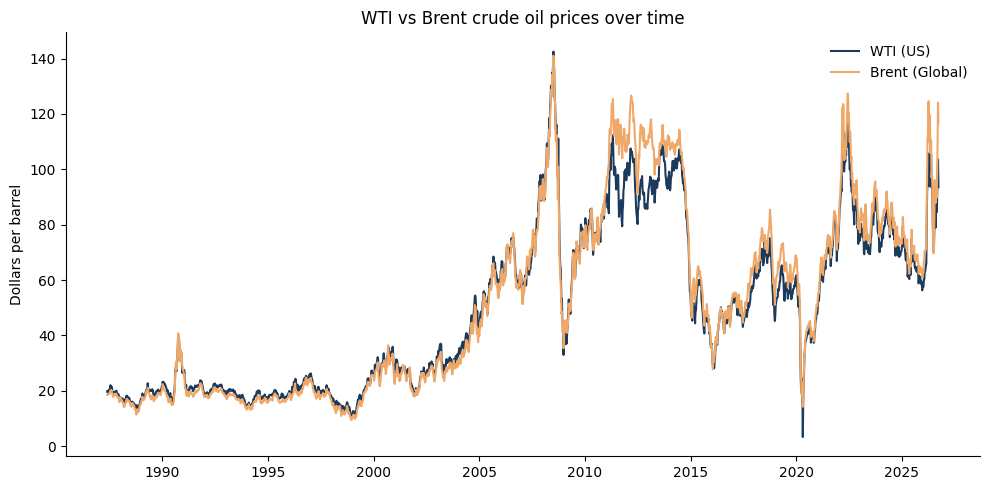

In [ ]:
import matplotlib.pyplot as plt
NAVY, RED, ORANGE = "#1B3A5C", "#D9534F", "#F0A868"

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(d["period"], d["RWTC"], color=NAVY, label="WTI (US)")
ax.plot(d["period"], d["RBRTE"], color=ORANGE, label="Brent (Global)")
ax.set_title("WTI vs Brent crude oil prices over time")
ax.set_ylabel("Dollars per barrel")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart1_price_trend.png", dpi=150); plt.show()

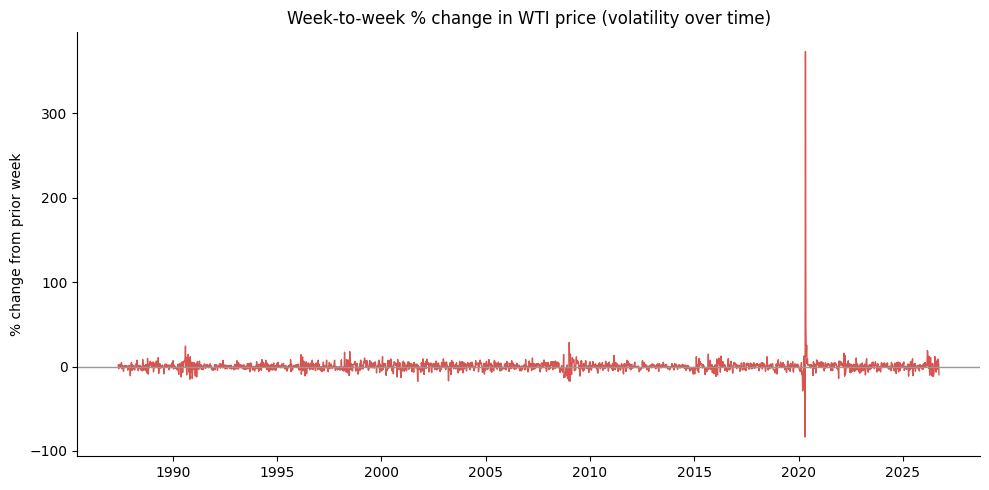

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(d["period"], d["wti_pct_change"], color=RED, linewidth=1)
ax.axhline(0, color="#999", linewidth=1)
ax.set_title("Week-to-week % change in WTI price (volatility over time)")
ax.set_ylabel("% change from prior week")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart2_volatility.png", dpi=150); plt.show()

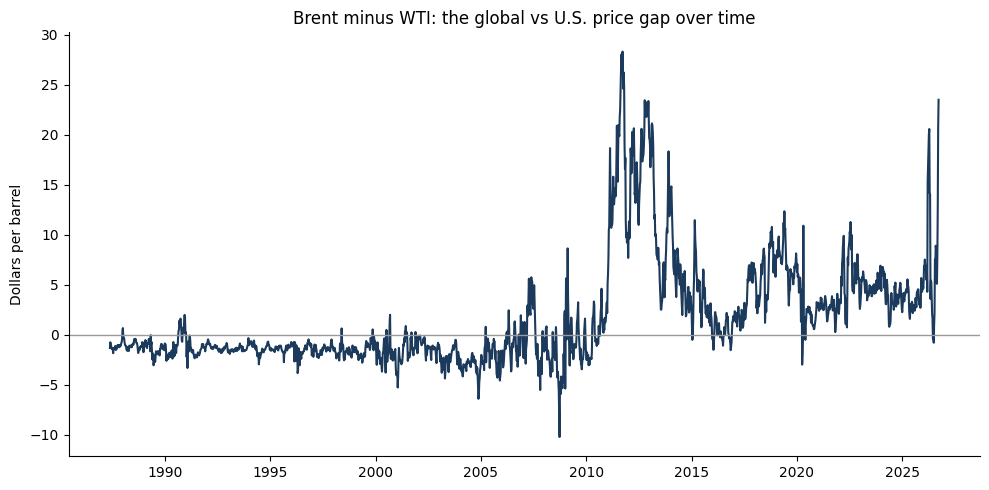

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(d["period"], d["brent_minus_wti"], color=NAVY)
ax.axhline(0, color="#999", linewidth=1)
ax.set_title("Brent minus WTI: the global vs U.S. price gap over time")
ax.set_ylabel("Dollars per barrel")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("chart3_brent_wti_gap.png", dpi=150); plt.show()

## Step 7: Save the clean numbers

This saves simple CSV files I'll use later to build the Looker Studio dashboard.

In [ ]:
d.to_csv("oil_price_weekly_clean.csv", index=False)
d.nlargest(10, "wti_pct_change")[["period","RWTC","wti_pct_change"]].to_csv("riskiest_weeks.csv", index=False)
print("Saved summary files.")

## Step 8: Say it in plain sentences

This prints out the findings as real sentences, filled in automatically with your actual numbers, not numbers I guessed.

In [ ]:
worst_spike = d.loc[d["wti_pct_change"].idxmax()]
worst_drop = d.loc[d["wti_pct_change"].idxmin()]

print(f'''
WHAT I FOUND (WTI and Brent crude oil prices, real EIA weekly data)

1. On an average week, WTI price moves about {d['wti_pct_change'].abs().mean():.2f}%, but the extremes are
   much bigger: the worst single-week spike was +{worst_spike['wti_pct_change']:.1f}% (week of {worst_spike['period'].date()}),
   and the worst single-week drop was {worst_drop['wti_pct_change']:.1f}% (week of {worst_drop['period'].date()}).

2. WTI and Brent move very closely together (correlation of {correlation:.2f} out of 1.0), so for a buyer,
   tracking just one of them gives a reasonably good sense of the other.

3. Brent trades about ${d['brent_minus_wti'].mean():.2f} per barrel above WTI on average, but this gap moves
   around over time rather than staying fixed, most recently sitting at ${d['brent_minus_wti'].iloc[-1]:.2f}.
''')


WHAT I FOUND (WTI and Brent crude oil prices, real EIA weekly data)

1. On an average week, WTI price moves about 3.42%, but the extremes are
   much bigger: the worst single-week spike was +373.2% (week of 2020-05-01),
   and the worst single-week drop was -83.5% (week of 2020-04-24).

2. WTI and Brent move very closely together (correlation of 0.99 out of 1.0), so for a buyer,
   tracking just one of them gives a reasonably good sense of the other.

3. Brent trades about $1.74 per barrel above WTI on average, but this gap moves
   around over time rather than staying fixed, most recently sitting at $23.51.



## Step 9: Limits of this analysis (honest notes)

- **Weekly prices, not daily.** Day-to-day spikes within a week aren't visible here, so true short-term volatility may be understated.
- **Spot prices only.** Most real buyers negotiate contracts, not spot-market purchases, so actual prices paid may differ from what's shown here.
- **Correlation is not causation**, especially for the production question, if that part of the analysis loaded at all.
- **No forward-looking prediction.** This describes historical patterns; it doesn't forecast future prices.

## Recommendations (what I would tell the procurement manager)

1. **Don't assume stability.** Even though average weekly moves look small, the extremes are large enough to disrupt a budget if a purchase happens to land in a bad week.
2. **WTI is a reasonable single indicator to watch**, given how closely it tracks Brent, if the company isn't especially sensitive to the small, shifting gap between the two.
3. **Watch the Brent-WTI gap itself** as a signal, when it widens sharply, it often reflects a regional supply or shipping issue worth knowing about before buying.

---
*Data source: U.S. Energy Information Administration (EIA), Petroleum Spot Prices, pulled live via the EIA API.*